# Steering angle analysis

This notebook will try to visualize a summary of steering angles around a track.

In [1]:
# Install packages
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import fastf1 as ff1

# Not sure what to call this
colormap = mpl.cm.plasma

# Define the current plot
year = 2025
race = 'Silverstone'
ses = 'R'
driver = 'NOR'

# Load F1 data
session = ff1.get_session(year, race, ses)
session.load()
lap = session.laps.pick_drivers(driver).pick_fastest()

x = lap.telemetry['X']
y = lap.telemetry['Y']

req         WARNING 	DEFAULT CACHE ENABLED! (4.65 GB) /Users/mjbernha/Library/Caches/fastf1
core           INFO 	Loading data for British Grand Prix - Race [v3.5.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['4', '81', '27', '44', '1', '10', '18', '23', '14', '63', '87', '55', '31', '16', '22'

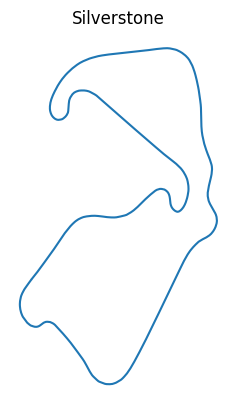

In [2]:
fig, ax = plt.subplots(1, 1)

ax.set_aspect('equal', 'box')
ax.set_title('Silverstone')
ax.axis('off')

ax.plot(
  x,y
)

In [3]:
lap.telemetry

,Date,SessionTime,DriverAhead,DistanceToDriverAhead,Time,RPM,Speed,nGear,Throttle,Brake,DRS,Source,Distance,RelativeDistance,Status,X,Y,Z
2,2025-07-06 15:33:34.768,0 days 02:25:54.155000,,NaN,0 days 00:00:00,11275.937222,262.187501,6,99.000000,False,0,interpolation,0.002359,4.061040e-07,OnTrack,-1690.452069,1296.850869,1963.631906
3,2025-07-06 15:33:34.848,0 days 02:25:54.235000,,NaN,0 days 00:00:00.080000,10928.937222,263.187501,6,99.000000,False,0,pos,5.858027,1.008290e-03,OnTrack,-1636.000000,1368.000000,1964.000000
4,2025-07-06 15:33:34.913,0 days 02:25:54.300000,,NaN,0 days 00:00:00.145000,10647.000000,264.000000,6,99.000000,False,0,car,10.641667,1.831655e-03,OnTrack,-1596.875305,1418.343600,1964.269835
5,2025-07-06 15:33:35.113,0 days 02:25:54.500000,,NaN,0 days 00:00:00.345000,10721.000000,267.000000,7,99.000000,False,0,car,25.475000,4.384783e-03,OnTrack,-1504.371038,1532.649425,1964.951615
6,2025-07-06 15:33:35.307,0 days 02:25:54.694000,,NaN,0 days 00:00:00.539000,10845.160082,267.970001,7,99.000000,False,0,pos,39.912953,6.869859e-03,OnTrack,-1421.000000,1637.000000,1966.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
676,2025-07-06 15:35:04.028,0 days 02:27:23.415000,,NaN,0 days 00:01:29.260000,11517.812541,251.583334,6,98.645834,False,0,pos,5769.092577,9.929822e-01,OnTrack,-1895.000000,1020.000000,1963.000000
677,2025-07-06 15:35:04.113,0 days 02:27:23.500000,,NaN,0 days 00:01:29.345000,11572.000000,253.000000,6,99.000000,False,0,car,5775.109444,9.940178e-01,OnTrack,-1863.782954,1063.116085,1963.079123
678,2025-07-06 15:35:04.348,0 days 02:27:23.735000,,NaN,0 days 00:01:29.580000,11647.640646,258.140626,6,99.000000,False,0,pos,5792.045521,9.969329e-01,OnTrack,-1808.000000,1139.000000,1963.000000
679,2025-07-06 15:35:04.433,0 days 02:27:23.820000,,NaN,0 days 00:01:29.665000,11675.000000,260.000000,6,99.000000,False,0,car,5798.220556,9.979957e-01,OnTrack,-1778.244073,1179.177006,1963.185353


In [4]:
tel = pd.DataFrame(lap.telemetry)
type(tel)

pandas.core.frame.DataFrame

In [5]:
tel['lastX'] = tel.X.shift()
tel['lastY'] = tel.Y.shift()
tel['nextX'] = tel.X.shift(-1)
tel['nextY'] = tel.Y.shift(-1)

In [6]:
tel

,Date,SessionTime,DriverAhead,DistanceToDriverAhead,Time,RPM,Speed,nGear,Throttle,Brake,...,Distance,RelativeDistance,Status,X,Y,Z,lastX,lastY,nextX,nextY
2,2025-07-06 15:33:34.768,0 days 02:25:54.155000,,NaN,0 days 00:00:00,11275.937222,262.187501,6,99.000000,False,...,0.002359,4.061040e-07,OnTrack,-1690.452069,1296.850869,1963.631906,NaN,NaN,-1636.000000,1368.000000
3,2025-07-06 15:33:34.848,0 days 02:25:54.235000,,NaN,0 days 00:00:00.080000,10928.937222,263.187501,6,99.000000,False,...,5.858027,1.008290e-03,OnTrack,-1636.000000,1368.000000,1964.000000,-1690.452069,1296.850869,-1596.875305,1418.343600
4,2025-07-06 15:33:34.913,0 days 02:25:54.300000,,NaN,0 days 00:00:00.145000,10647.000000,264.000000,6,99.000000,False,...,10.641667,1.831655e-03,OnTrack,-1596.875305,1418.343600,1964.269835,-1636.000000,1368.000000,-1504.371038,1532.649425
5,2025-07-06 15:33:35.113,0 days 02:25:54.500000,,NaN,0 days 00:00:00.345000,10721.000000,267.000000,7,99.000000,False,...,25.475000,4.384783e-03,OnTrack,-1504.371038,1532.649425,1964.951615,-1596.875305,1418.343600,-1421.000000,1637.000000
6,2025-07-06 15:33:35.307,0 days 02:25:54.694000,,NaN,0 days 00:00:00.539000,10845.160082,267.970001,7,99.000000,False,...,39.912953,6.869859e-03,OnTrack,-1421.000000,1637.000000,1966.000000,-1504.371038,1532.649425,-1418.233017,1640.568012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
676,2025-07-06 15:35:04.028,0 days 02:27:23.415000,,NaN,0 days 00:01:29.260000,11517.812541,251.583334,6,98.645834,False,...,5769.092577,9.929822e-01,OnTrack,-1895.000000,1020.000000,1963.000000,-1983.397726,897.392493,-1863.782954,1063.116085
677,2025-07-06 15:35:04.113,0 days 02:27:23.500000,,NaN,0 days 00:01:29.345000,11572.000000,253.000000,6,99.000000,False,...,5775.109444,9.940178e-01,OnTrack,-1863.782954,1063.116085,1963.079123,-1895.000000,1020.000000,-1808.000000,1139.000000
678,2025-07-06 15:35:04.348,0 days 02:27:23.735000,,NaN,0 days 00:01:29.580000,11647.640646,258.140626,6,99.000000,False,...,5792.045521,9.969329e-01,OnTrack,-1808.000000,1139.000000,1963.000000,-1863.782954,1063.116085,-1778.244073,1179.177006
679,2025-07-06 15:35:04.433,0 days 02:27:23.820000,,NaN,0 days 00:01:29.665000,11675.000000,260.000000,6,99.000000,False,...,5798.220556,9.979957e-01,OnTrack,-1778.244073,1179.177006,1963.185353,-1808.000000,1139.000000,-1749.274561,1218.241543


In [7]:
# Calculate the steering angle
# X, Y is the current position of the car
# lastX, lastY is the previous position of the car
# nextX, nextY is the next position of the car
# ldX, ldY is the offset from current to last position
# ndX, ndY is the offset from current to next position
# degrees(atan2())
import math

#ldX = X - lastX
#ldY = Y - lastY
#ndX = nextX - X
#ndY = nextY - Y
tel['ldX'] = tel['X'] - tel['lastX']
tel['ldY'] = tel['Y'] - tel['lastY']
tel['ndX'] = tel['nextX'] - tel['X']
tel['ndY'] = tel['nextY'] - tel['Y']

In [8]:
tel['lastAngle'] = np.arctan2(tel['ldX'],tel['ldY'])
tel['nextAngle'] = np.arctan2(tel['ndX'],tel['ndY'])

In [9]:

tel['SteeringAngle'] = np.degrees(
  tel['lastAngle'] - tel['nextAngle']
)

In [10]:
tel

,Date,SessionTime,DriverAhead,DistanceToDriverAhead,Time,RPM,Speed,nGear,Throttle,Brake,...,lastY,nextX,nextY,ldX,ldY,ndX,ndY,lastAngle,nextAngle,SteeringAngle
2,2025-07-06 15:33:34.768,0 days 02:25:54.155000,,NaN,0 days 00:00:00,11275.937222,262.187501,6,99.000000,False,...,NaN,-1636.000000,1368.000000,NaN,NaN,54.452069,71.149131,NaN,0.653236,NaN
3,2025-07-06 15:33:34.848,0 days 02:25:54.235000,,NaN,0 days 00:00:00.080000,10928.937222,263.187501,6,99.000000,False,...,1296.850869,-1596.875305,1418.343600,54.452069,71.149131,39.124695,50.343600,0.653236,0.660654,-0.425021
4,2025-07-06 15:33:34.913,0 days 02:25:54.300000,,NaN,0 days 00:00:00.145000,10647.000000,264.000000,6,99.000000,False,...,1368.000000,-1504.371038,1532.649425,39.124695,50.343600,92.504267,114.305826,0.660654,0.680368,-1.129521
5,2025-07-06 15:33:35.113,0 days 02:25:54.500000,,NaN,0 days 00:00:00.345000,10721.000000,267.000000,7,99.000000,False,...,1418.343600,-1421.000000,1637.000000,92.504267,114.305826,83.371038,104.350575,0.680368,0.674101,0.359050
6,2025-07-06 15:33:35.307,0 days 02:25:54.694000,,NaN,0 days 00:00:00.539000,10845.160082,267.970001,7,99.000000,False,...,1532.649425,-1418.233017,1640.568012,83.371038,104.350575,2.766983,3.568012,0.674101,0.659621,0.829681
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
676,2025-07-06 15:35:04.028,0 days 02:27:23.415000,,NaN,0 days 00:01:29.260000,11517.812541,251.583334,6,98.645834,False,...,897.392493,-1863.782954,1063.116085,88.397726,122.607507,31.217046,43.116085,0.624669,0.626668,-0.114510
677,2025-07-06 15:35:04.113,0 days 02:27:23.500000,,NaN,0 days 00:01:29.345000,11572.000000,253.000000,6,99.000000,False,...,1020.000000,-1808.000000,1139.000000,31.217046,43.116085,55.782954,75.883915,0.626668,0.633903,-0.414533
678,2025-07-06 15:35:04.348,0 days 02:27:23.735000,,NaN,0 days 00:01:29.580000,11647.640646,258.140626,6,99.000000,False,...,1063.116085,-1778.244073,1179.177006,55.782954,75.883915,29.755927,40.177006,0.633903,0.637471,-0.204474
679,2025-07-06 15:35:04.433,0 days 02:27:23.820000,,NaN,0 days 00:01:29.665000,11675.000000,260.000000,6,99.000000,False,...,1139.000000,-1749.274561,1218.241543,29.755927,40.177006,28.969513,39.064537,0.637471,0.638091,-0.035506


In [11]:
# TODO: Figure out why some datapoints are outliers at -358 and 353
tel['SteeringAngle'].describe()

count    677.000000
mean       0.001282
std       23.903664
min     -358.372575
25%       -2.235857
50%       -0.189425
75%        0.862541
max      353.430407
Name: SteeringAngle, dtype: float64

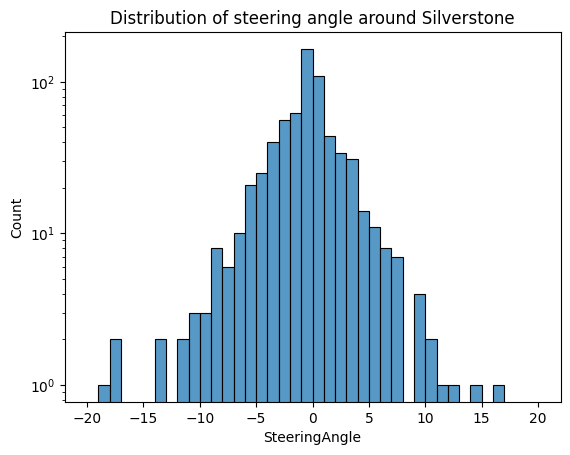

In [12]:
sns.histplot(
  tel['SteeringAngle'],
  binrange=(-20,20),
  bins=40
)
plt.title('Distribution of steering angle around Silverstone')
plt.yscale('log')
plt.show()

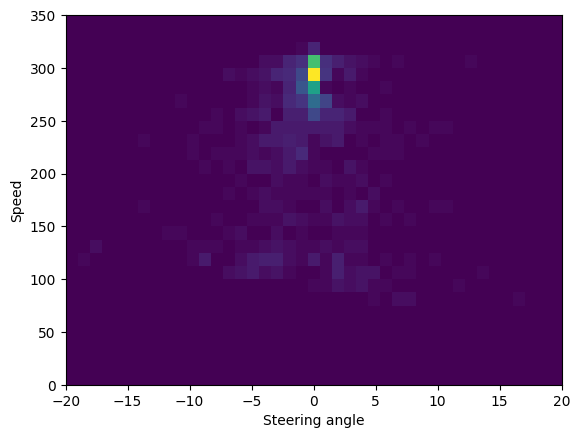

In [13]:
# TODO: Heatmap(??) comparing steering angle to speed and/or throttle
plt.hist2d(
  tel['SteeringAngle'],
  tel['Speed'],
  bins=[41,28],
  range=[[-20,20],[0,350]]
)
plt.xlabel('Steering angle')
plt.ylabel('Speed')
plt.show()

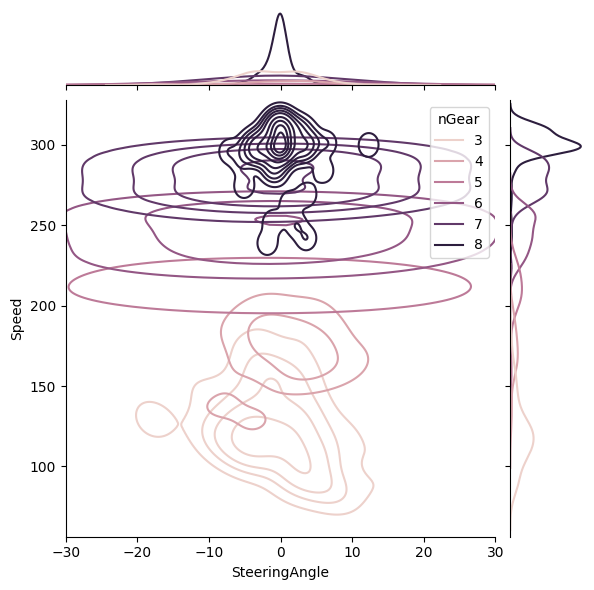

In [36]:
sns.jointplot(
  x=tel['SteeringAngle'],
  y=tel['Speed'],
  kind="kde",
  color="#5899C6",
  hue=tel['nGear'],
  xlim=(-30,30),
  dropna=True
)

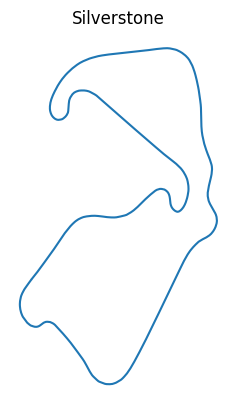

In [14]:
# TODO: color code map by steering angle
fig, ax = plt.subplots(1, 1)

ax.set_aspect('equal', 'box')
ax.set_title('Silverstone')
ax.axis('off')

ax.plot(
  x,y
)

---

This is the end of the notebook.